# Migrating to ns-3.42

**Done on this branch.** MoReV2X now runs on the CTTC v2x tree, ns-3.42, the base of the groupcast work. `develop` stays on ns-3.22.

The port passes all its tests, and Mode 2 results match ns-3.22 within the confidence intervals. See [the result](#result-of-the-port). The assessment below is kept as written before the port, with one correction.

## Verdict

**Migration is possible, and the code gap is small. The real risk is unnoticed change in Mode 2 results, and it can be controlled.** It would only pay off if MoReV2X had to share a tree with the groupcast work.

Latest release on 2026-11-06: **ns-3.49**. MoReV2X is on ns-3.22, from February 2015.

| | Evidence |
|---|---|
| Possible? | 64 of 79 sources already type-check against ns-3.49, and the 70 errors in the rest have known fixes |
| Blocking stock patches? | None. **Corrected:** this said the patches were debug logging. One of them is what applies MoReV2X's shadowing, see below |
| Dependency on stock LTE? | None in the source: no stock `lte-*` header is included |
| Clash with 5G-LENA? | No class name collides, across 404 MoReV2X classes |
| Main risk | Results change without any error. Addressed with statistical comparison before and after |

**What was not done:** nothing was built, linked or run on a new ns-3. This is a compile-only trial. It finds API breaks, not behaviour changes, so it says the port is feasible, not that it works.

## The trial

Each source of `src/MoReV2X`, `src/traci` and `scratch/HIGHWAY.cc` was type-checked with `clang++ -fsyntax-only`. Nothing from either tree was executed, and nothing was written to the groupcast tree.

| Target | Standard | Files with errors | Errors |
|---|---|---|---|
| ns-3.42, your groupcast tree | C++20 | 12 of 79 | 48 |
| ns-3.49, latest | C++23 | 15 of 79 | 70 |
| ns-3.49, starting from carlosrisma's 3.36 port | C++23 | 13 of 79 | 55 |

Raw errors are in `docs/notebooks/data/`, and the script in `tools/ns3_compile_trial.py`. The 3.49 count includes 6 errors from the trial's own header stubs.

**carlosrisma's port saves only 15 errors.** It is not a useful starting point: you would inherit its rename and lose this repository's changes.

In [1]:
import os, subprocess, sys
sys.path.insert(0, os.path.abspath("../../tools"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
mr.apply_chart_style()
os.chdir(mr.ROOT)

In [2]:
import collections, re

RULES = [
    ("Ptr compared with 0", r"Ptr<.*'(int|long)'"),
    ("EventId::IsRunning renamed IsPending", r"IsRunning"),
    ("GetRxAntenna renamed, returns Ptr<Object>", r"GetRxAntenna|AntennaModel \\*"),
    ("UdpClient::m_peerAddress renamed", r"m_peerAddress"),
    ("Angles fields became getters", r"'phi'|'theta'"),
    ("SpectrumPhy pure virtuals", r"abstract class"),
    ("Object rules: CreateObject, final GetInstanceTypeId", r"CreateObject|GetInstanceTypeId"),
    ("BuildingsHelper call removed", r"MakeMobilityModelConsistent"),
    ("MakeEnumAccessor needs a template argument", r"MakeEnumAccessor"),
    ("SocketAddressTag removed", r"SocketAddressTag"),
    ("Logging of a NIST type", r"basic_ostream"),
    ("Artefact of the trial headers", r"redefinition of"),
]
def classify(path):
    counts = collections.Counter()
    for line in open(path):
        if " error: " not in line:
            continue
        message = line.split(" error: ", 1)[1]
        counts[next((name for name, rule in RULES if re.search(rule, message)), "other")] += 1
    return counts

table = pd.DataFrame({version: classify(f"docs/notebooks/data/ns3-trial-{version}-errors.txt") for version in ("3.42", "3.49")})
table.fillna(0).astype(int).sort_values("3.49", ascending=False)

,3.42,3.49
Ptr compared with 0,34,34
EventId::IsRunning renamed IsPending,0,9
"GetRxAntenna renamed, returns Ptr<Object>",7,7
Artefact of the trial headers,0,6
UdpClient::m_peerAddress renamed,0,4
"Object rules: CreateObject, final GetInstanceTypeId",0,3
Angles fields became getters,2,2
SpectrumPhy pure virtuals,1,1
SocketAddressTag removed,1,1
Logging of a NIST type,1,1


## Every break, and its fix

| Break | Mode 2 path? | Fix |
|---|---|---|
| `Ptr == 0`, no longer compiles | Yes, also in `nr-v2x-spectrum-phy.cc` | Mechanical: `if (!ptr)` |
| `EventId::IsRunning` | Yes, 2 in `nr-v2x-rlc-um.cc` | Rename to `IsPending` |
| `GetRxAntenna`, `SpectrumPhy` pure virtuals | **Yes**, `NrV2XSpectrumPhy` becomes abstract | Add `GetAntenna`, and make `GetDevice` and `GetMobility` const, as carlosrisma did |
| `Angles.phi`, `.theta` | Antenna model | `GetAzimuth`, `GetInclination`. Check the angle convention against the old values |
| `m_peerAddress` in `UdpClient` | **Yes**, the scenario's traffic | See risk 2 |
| `Create<LTENodeState>`, `GetInstanceTypeId` | Scenario | `CreateObject`, delete the override |
| `BuildingsHelper::MakeMobilityModelConsistent` | Scenario | Delete the call |
| `MakeEnumAccessor` | `nist-lte-amc.cc` | Add the template argument |
| `SocketAddressTag` | No, EPC | Comment out, as carlosrisma did. Out of scope |

## Risks a type-check cannot see

Ordered by how much they matter for Mode 2.

| # | Risk | Severity | How to address it |
|---|---|---|---|
| 1 | **Silent drift of Mode 2 results.** `MultiModelSpectrumChannel`, the interference chain and event ordering have 10 years of changes. The code would run and give different numbers. RNG order changes too, so `tools/fingerprint.sh` cannot cross versions | **High** | Compare distributions, not hashes. Before porting, run a `tools/run_sweep.py` baseline on 3.22 with 10 or more `runNo` across loads and modes. After porting, PDR by distance, collisions, CBR and latency must fall inside the confidence intervals. A difference is a finding to explain before using the port |
| 2 | **The `UdpClient::Send` override.** `HIGHWAY` redefines a stock method, and needed `weak` patches in stock files on macOS. It would have to be redone in every version | Medium, certain | Replace it with a `V2xTrafficApplication` class of ours. This can be done on 3.22 first, where `fingerprint.sh` proves it changes nothing. Worth doing even without migrating |
| 3 | **Runtime-only names.** `ns3::DropTailQueue::MaxPackets` no longer exists, and `Config::SetDefault` aborts at startup | Low | Delete the line or use `MaxSize`. Runs fail loudly |
| 4 | **New assertions** in debug builds on code that relies on loose behaviour | Medium | `tools/debug-check.sh` covers 22 modes. It found 2 real bugs on 3.22 |
| 5 | **Undefined behaviour hidden by old compilers.** `Mode2Step1` uses `erase` followed by `--` on `std::list` iterators, which only works at `begin()` because libc++ lists are circular. Uninitialised members have already been found | Medium | Run the scenarios once under AddressSanitizer and UBSan. Newer ns-3 and libc++ hardening make this more likely to surface |
| 6 | **Build system.** waf to CMake, for 3 modules and the tests | Low | carlosrisma's `CMakeLists.txt` and the groupcast one for `traci` are reusable. It also removes the Python 2.7 dependency |
| 7 | **macOS.** Apple clang parsed C++23 here, but linking and `weak` behaviour are untested on new ns-3 | Low | Goes away with risk 2 |
| 8 | **Rebasing later.** Upstream's README said a port was underway. Its last push was March 2024 | Low | Ask the authors before starting, in case one exists |
| 9 | **EPC code.** `HIGHWAY` only uses it for a gateway address, and it holds the out-of-scope breaks | Low | Can be cut from the scenario |

## What does not need carrying over

Upstream altered 13 stock files. For Mode 2:

| Patch | Needed? |
|---|---|
| `propagation-loss-model.cc` | No. Debug files, including the 450 MB `.unimo` logs. `TwoRay` default frequency is unused, since MoReV2X has its own model |
| `multi-model-spectrum-channel.*` | No. Adds a `Gain` trace that never fires |
| `buildings-propagation-loss-model.*` | **Yes. This row said "No, debug prints", which was wrong.** The `.h` patch made `GetShadowing` virtual, and without it MoReV2X's shadowing is skipped. Replaced by an override in `NrV2XPropagationLossModel`, no stock patch needed |
| `callback.h` | No. Modern ns-3 callbacks take any number of arguments |
| `ns2-mobility-helper.h` | No. Unused |
| `udp-client.*`, `packet-sink` | Only for the override, see risk 2 |

## The options

| Option | Gain for Mode 2 | Cost | When it makes sense |
|---|---|---|---|
| **A. Stay on 3.22** | Everything is verified today | None now. Python 2.7 and a 2015 base stay | Your work is Mode 2 scheduling inside MoReV2X |
| **B. Port to 3.42** | **Same base as your groupcast tree**: compare MoReV2X and 5G-LENA Mode 2 on the same SUMO scenarios with one TraCI module | Smallest port, 48 errors | You want both simulators in one tree |
| **C. Port to 3.49** | Latest ns-3, no Python 2 | 22 more errors, C++23. **5G-LENA's sidelink stays behind**: its newest `v2x-v1.1` is tied to ns-3.42 | You need a feature of recent ns-3 |

**No option adds a Mode 2 feature.** New ns-3 gives no sidelink behaviour to MoReV2X, whose MAC and PHY are its own. Migrating buys maintainability and co-existence, not results.

**Chosen: B, on this branch.** B to C later is a small step.

## The plan that was followed

Each step goes through `tools/gate.sh`. Effort is a rough estimate of working days, and step 4 is the unknown.

| Step | Work | Effort |
|---|---|---|
| 1 | Baseline: `run_sweep.py` over loads and modes, 10+ seeds | 1, mostly compute |
| 2 | Replace the `UdpClient` override, on 3.22, proven by `fingerprint.sh` | 1 |
| 3 | Port: fixes above, CMake, tests, `debug-check.sh`, sanitizers | 2 to 3 |
| 4 | Validate against the baseline, and explain each difference | 2 to 5, open-ended if drift appears |

Steps 1 and 2 are useful on their own, and they are the moment to stop if the numbers argue against going on.

## Result of the port

| Check | Result |
|---|---|
| Build | All sources build on ns-3.42 |
| ns-3 tests | 239 of 239 suites pass, with `nr-v2x-mode2`, `sumo-mobility` and `lte-x2-handover` among them |
| Assertions | 22 of 22 modes pass in `tools/debug-check.sh` |
| Scenario tests | All pass, including live SUMO and trace replay |
| Against ns-3.22 | **0 of 140 KPI comparisons differ**, and 0 of 14 on identical mobility |

### What the compile trial missed

The 48 predicted errors were fixed as planned, with no surprises. These were the real problems, and none shows up as a compile error:

| Problem | Effect | Fix |
|---|---|---|
| `SpectrumSignalParameters::Copy` became `const`, so the 6 MoReV2X `Copy ()` methods stopped overriding it | Signals sliced, crash at the first reception | Added `const` and `override` |
| `GetShadowing` is not virtual in stock ns-3 | **Silent.** No NLOSv or MoReV2X shadowing: PDR at 1.1 km went from 0.76 to 0.99, and "below sensitivity" from 37 % to 2 % | `NrV2XPropagationLossModel::DoCalcRxPower` |
| `DropTailQueue::MaxPackets` removed | Abort at startup | `MaxSize` |
| A debug-only assert on "not enough resources for a re-transmission" | Random, also possible on 3.22. The next line of upstream's code handles the case | Assert removed |

The second one is the reason for the baseline. It ran normally, gave plausible curves, and passed every unit test. The first was found by a crash, and a search with `-Woverloaded-virtual` then showed there were no others of its kind, among 241 overriding methods.

### Validation

Each group was run on both versions with 5 seeds, 10 s, and the same YAML: 60 and 120 vehicles, with all combinations of `ReTx` and `ReEvaluation`, plus `Dynamic`. A KPI counts as different when the 95 % confidence intervals of the two means do not overlap. Seeds are not paired, since the random draws differ between versions.

The KPIs are PDR in 6 distance bands, the share of each loss type, CBR, mean latency, selections and transmissions.

In [3]:
validation = pd.concat(pd.read_csv(f"docs/notebooks/data/migration-validation-{name}.csv") for name in ("sps", "dynamic"))
print(len(validation), "comparisons,", int(validation.differs.sum()), "differ")
pdr = validation[validation.kpi.str.startswith("PDR")].assign(gap=lambda t: t.after - t.before)
print(f"PDR, mean absolute gap {pdr.gap.abs().mean():.4f}, largest {pdr.gap.abs().max():.4f}, mean signed gap {pdr.gap.mean():+.4f}")
pdr.pivot_table(index="group", columns="kpi", values="gap").round(3)

140 comparisons, 0 differ
PDR, mean absolute gap 0.0086, largest 0.0286, mean signed gap +0.0082


kpi,PDR 0-100 m,PDR 100-300 m,PDR 1200-2000 m,PDR 300-500 m,PDR 500-800 m,PDR 800-1200 m
group,,,,,,
Vehicles120,0.003,0.007,0.006,0.015,0.017,0.014
Vehicles120_ReEvaluationFalse_ReTxFalse,0.003,0.004,0.014,0.016,0.025,0.023
Vehicles120_ReEvaluationFalse_ReTxTrue,-0.000,0.002,0.010,0.005,0.023,0.016
Vehicles120_ReEvaluationTrue_ReTxFalse,0.002,0.007,0.011,0.016,0.020,0.018
Vehicles120_ReEvaluationTrue_ReTxTrue,-0.001,0.001,0.013,0.011,0.025,0.029
Vehicles60,0.006,0.010,0.001,0.012,0.013,-0.000
Vehicles60_ReEvaluationFalse_ReTxFalse,-0.003,0.002,0.005,0.004,0.009,-0.004
Vehicles60_ReEvaluationFalse_ReTxTrue,-0.000,0.001,0.003,0.003,0.013,0.003
Vehicles60_ReEvaluationTrue_ReTxFalse,-0.003,0.005,0.008,0.010,0.014,0.011


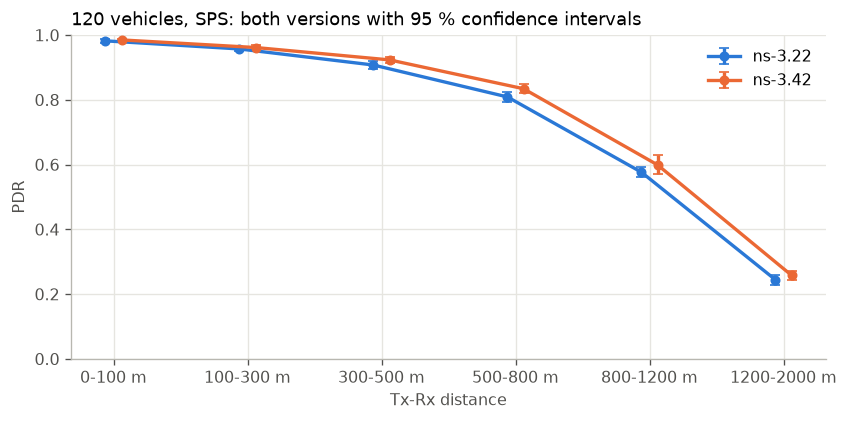

In [4]:
group = "Vehicles120_ReEvaluationFalse_ReTxFalse"
bands = ["PDR 0-100 m", "PDR 100-300 m", "PDR 300-500 m", "PDR 500-800 m", "PDR 800-1200 m", "PDR 1200-2000 m"]
table = validation[(validation.group == group)].set_index("kpi").loc[bands]
fig, ax = plt.subplots()
x = np.arange(len(bands))
ax.errorbar(x - 0.06, table.before, yerr=table.before_ci, fmt="o-", color=mr.SERIES_COLORS[0], capsize=3, label="ns-3.22")
ax.errorbar(x + 0.06, table.after, yerr=table.after_ci, fmt="o-", color=mr.SERIES_COLORS[1], capsize=3, label="ns-3.42")
ax.set_xticks(x, [b.replace("PDR ", "") for b in bands])
ax.set_xlabel("Tx-Rx distance")
ax.set_ylabel("PDR")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("120 vehicles, SPS: both versions with 95 % confidence intervals")
plt.tight_layout()

**Reading.** No single KPI differs, but this table alone is not enough. The gaps nearly all lean the same way: ns-3.42 shows higher PDR, with lower CBR and fewer collisions, in every group.

That lean has a simple cause. Placement is drawn before the scheduler options, so all modes with the same seed share one placement, and the two versions draw different ones. These 10 groups therefore hold only 5 placements per load, per version. Below-sensitivity curves confirmed it: the power shift between versions is 0.0 +/- 0.2 dB, while the median Tx-Rx distance of those runs differed.

So the decisive test removes placement: the same SUMO trace on both versions, 8 seeds.

In [5]:
same = pd.read_csv("docs/notebooks/data/migration-validation-same-trace.csv")
print(len(same), "comparisons on identical mobility,", int(same.differs.sum()), "differ")
same[["kpi", "before", "before_ci", "after", "after_ci"]].rename(columns={"before": "ns-3.22", "after": "ns-3.42"}).round(4)

14 comparisons on identical mobility, 0 differ


,kpi,ns-3.22,before_ci,ns-3.42,after_ci
0,collisions,0.1421,0.0058,0.1403,0.0051
1,below sensitivity,0.0340,0.0006,0.0342,0.0007
2,half duplex,0.0122,0.0003,0.0124,0.0003
3,propagation,0.0400,0.0006,0.0401,0.0004
4,CBR,0.2169,0.0010,0.2166,0.0012
5,latency mean ms,29.5468,0.4921,29.6325,0.8791
6,selections,777.3750,6.0979,774.2500,7.0200
7,transmissions,13432.2500,41.2030,13425.2500,30.1098
8,PDR 0-100 m,0.9810,0.0030,0.9812,0.0031
9,PDR 100-300 m,0.9428,0.0031,0.9448,0.0072


**Result.** On identical mobility, the two versions agree closely: CBR 0.2169 and 0.2166, collisions 14.2 % and 14.0 %, and no PDR band further apart than 0.003. The lean in the first table came from placement.

When comparing two versions or two schedulers, use `--mobilityTrace`. It removes the largest source of variance, and it found in 8 seeds what the first sweep could not show in 50 runs.

## Limits of this validation

- **The trace test covers one configuration.** Periodic SPS at about 33 vehicles per km. ReTx, re-evaluation and dynamic were only compared in the sweep, whose 5-seed intervals are wider.
- **It does not cover everything.** Aperiodic and mixed traffic, other numerologies, `--AdaptiveRRI` and SUMO scenarios ran without errors, but were not compared against 3.22.
- **Results from `develop` and this branch should not be mixed in one study.** Even a small shift matters at that level.
- **`contrib/nr` is not in this tree.** The port uses the same base, but MoReV2X and 5G-LENA have not been built together. No class names collide, which is all that has been checked.